[[-1 -1]
 [-2 -1]
 [-3 -2]
 [ 1  1]
 [ 2  1]
 [ 3  2]]


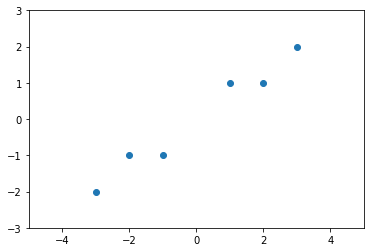

In [12]:
import numpy as np
import matplotlib.pyplot as plt
X = np.array([[-1, -1], [-2, -1], [-3, -2], [1, 1], [2, 1], [3, 2]])
print(X)
plt.scatter(X[:,0],X[:,1])
plt.xlim([-5,5])
plt.ylim([-3,3])
plt.show()

Principal Components
[[-0.83849224  0.54491354]
 [-0.54491354 -0.83849224]]
Principal Components
[[-0.83849224  0.54491354]
 [-0.54491354 -0.83849224]]
Variance
[7.93954312 0.06045688]
Variance
[7.93954312 0.06045688]
Importance of Each Component
[0.99244289 0.00755711]
New Features
[[ 1.38340578  0.2935787 ]
 [ 2.22189802 -0.25133484]
 [ 3.6053038   0.04224385]
 [-1.38340578 -0.2935787 ]
 [-2.22189802  0.25133484]
 [-3.6053038  -0.04224385]]


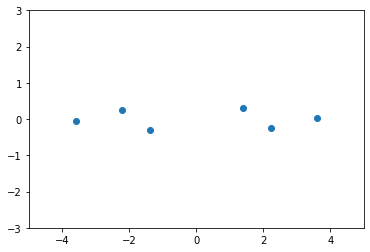

Recover from 2 components
[[-1. -1.]
 [-2. -1.]
 [-3. -2.]
 [ 1.  1.]
 [ 2.  1.]
 [ 3.  2.]]
Recover from 1 component
[[-1.15997501 -0.75383654]
 [-1.86304424 -1.21074232]
 [-3.02301925 -1.96457886]
 [ 1.15997501  0.75383654]
 [ 1.86304424  1.21074232]
 [ 3.02301925  1.96457886]]


In [13]:
X = X - X.mean(axis=0)
Sigma = X.T.dot(X)/(X.shape[0]-1)
[U1,S1,V1] = np.linalg.svd(Sigma)
[S2, U2] = np.linalg.eig(Sigma)
print("Principal Components")
U1[:,1] = U1[:,1]/(-1)
print(U1)
print("Principal Components")
U2 = U2/(-1)
print(U2)
print("Variance")
print(S1)
print("Variance")
print(S2)
print("Importance of Each Component")
print(S1/(S1[0]+S1[1]))

# Make U1 the same as sklearn function result
Z = X.dot(U1)
print("New Features")
print(Z)
plt.scatter(Z[:,0], Z[:,1])
plt.xlim([-5,5])
plt.ylim([-3,3])
plt.show()

print("Recover from 2 components")
print(Z.dot(U1.T))
print("Recover from 1 component")
Z_1component = np.expand_dims(X.dot(U1[:,0]),axis=1)
print(Z_1component.dot(U1[:,:1].T))

Principal Components
[[-0.83849224  0.54491354]
 [-0.54491354 -0.83849224]]
Variance
[7.93954312 0.06045688]
Importance of Each Component
[0.99244289 0.00755711]
New Features
[[ 1.38340578  0.2935787 ]
 [ 2.22189802 -0.25133484]
 [ 3.6053038   0.04224385]
 [-1.38340578 -0.2935787 ]
 [-2.22189802  0.25133484]
 [-3.6053038  -0.04224385]]


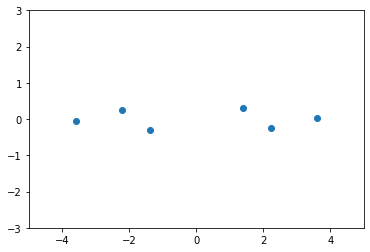

Recover from 2 components
[[-1. -1.]
 [-2. -1.]
 [-3. -2.]
 [ 1.  1.]
 [ 2.  1.]
 [ 3.  2.]]
Recover from 1 component
[[ 1.38340578]
 [ 2.22189802]
 [ 3.6053038 ]
 [-1.38340578]
 [-2.22189802]
 [-3.6053038 ]]
[[-1.15997501 -0.75383654]
 [-1.86304424 -1.21074232]
 [-3.02301925 -1.96457886]
 [ 1.15997501  0.75383654]
 [ 1.86304424  1.21074232]
 [ 3.02301925  1.96457886]]


In [14]:
import numpy as np
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(X)
print("Principal Components")
print(pca.components_.T)
print("Variance")
print(pca.explained_variance_)
print("Importance of Each Component")
print(pca.explained_variance_ratio_)

Z = pca.transform(X)
print("New Features")
print(Z)
plt.scatter(Z[:,0], Z[:,1])
plt.xlim([-5,5])
plt.ylim([-3,3])
plt.show()

print("Recover from 2 components")
print(pca.inverse_transform(Z))
pca_1component = PCA(n_components=1).fit(X)
print("Recover from 1 component")
print(pca_1component.transform(X))
print(pca_1component.inverse_transform(pca_1component.transform(X)))